<a href="https://colab.research.google.com/github/skandanyal/ML-Lab-7th-sem/blob/main/mlLab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Install Required Library
Since K-Medoids is not in standard `scikit-learn`, we will install `scikit-learn-extra` to access it.

In [1]:
!pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 8.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2156376 sha256=086f7ff1093e8411a4287ba4a168e55984654597b1c61a9021f37fe0912adf9f
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


### 2. Load and Prepare the Dataset
We will use the California Housing dataset's latitude and longitude features for geographical clustering. Since the dataset is large, we'll downsample it to 2,000 points to ensure fast and readable visualizations.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler

# Load dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.sample(n=2000, random_state=42).reset_index(drop=True)

# We will use Latitude and Longitude for geographical clustering
coords = df[['Latitude', 'Longitude']]

# Scale the features for distance-based algorithms
scaler = StandardScaler()
coords_scaled = scaler.fit_transform(coords)

print(f"Dataset downsampled to {coords.shape[0]} samples.")
display(coords.head())

Dataset downsampled to 2000 samples.


,Latitude,Longitude
0,36.06,-119.01
1,35.14,-119.46
2,37.80,-122.44
3,34.28,-118.72
4,36.62,-121.93


### 3. K-Means Clustering

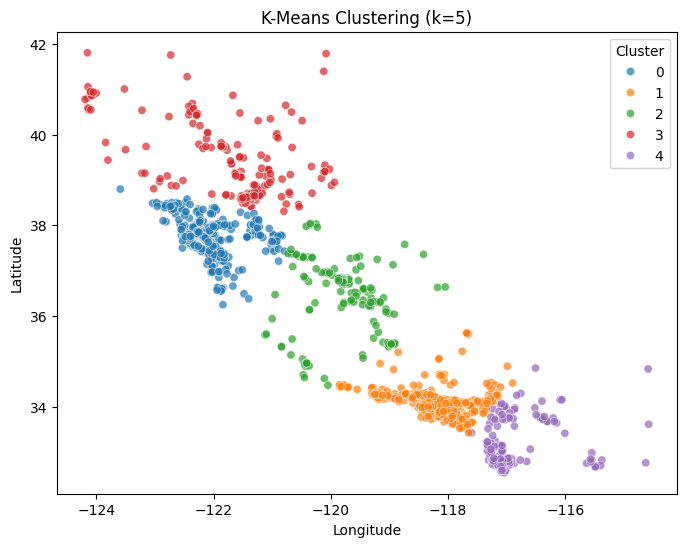

In [3]:
from sklearn.cluster import KMeans

# Apply K-Means
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['KMeans_Labels'] = kmeans.fit_predict(coords_scaled)

# Plot K-Means result
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Longitude', y='Latitude', hue='KMeans_Labels', palette='tab10', alpha=0.7)
plt.title('K-Means Clustering (k=5)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Cluster')
plt.show()

### 4. DBSCAN Clustering (Density-Based)

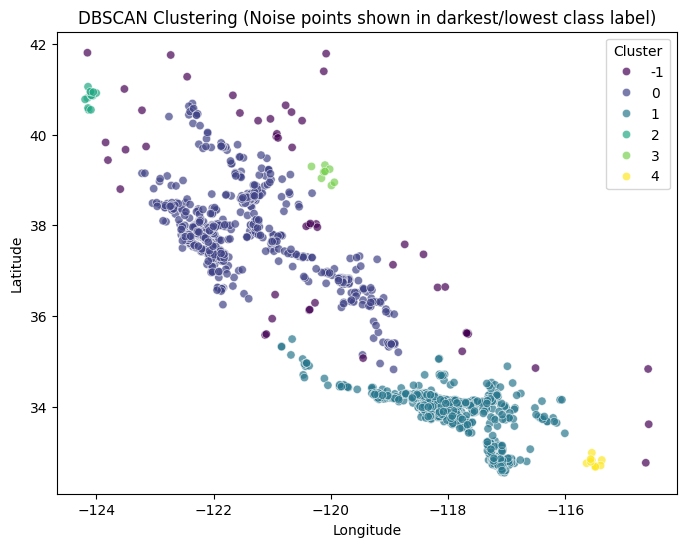

In [4]:
from sklearn.cluster import DBSCAN

# Apply DBSCAN (eps and min_samples tuned for scaled coordinates)
dbscan = DBSCAN(eps=0.2, min_samples=10)
df['DBSCAN_Labels'] = dbscan.fit_predict(coords_scaled)

# Plot DBSCAN result (-1 indicates noise/outliers)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Longitude', y='Latitude', hue='DBSCAN_Labels', palette='viridis', alpha=0.7)
plt.title('DBSCAN Clustering (Noise points shown in darkest/lowest class label)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Cluster')
plt.show()

### 5. K-Medoids Clustering
K-Medoids uses actual data points as centers (exemplars) and is more robust to noise and outliers compared to K-Means.

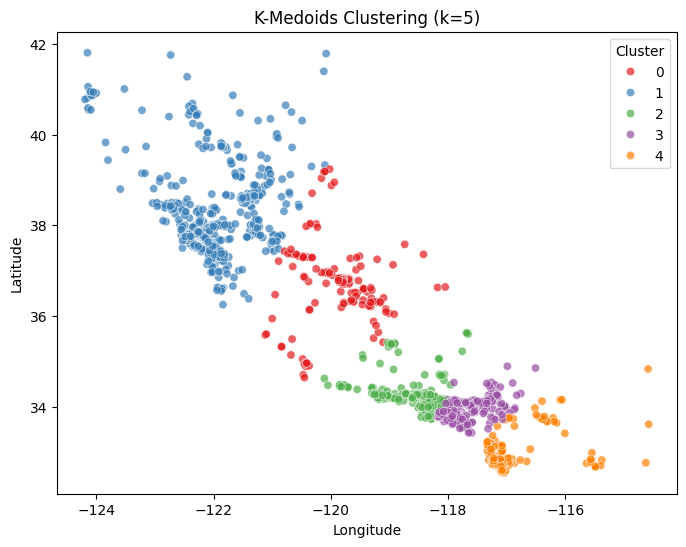

In [5]:
from sklearn_extra.cluster import KMedoids

# Apply K-Medoids
kmedoids = KMedoids(n_clusters=5, random_state=42)
df['KMedoids_Labels'] = kmedoids.fit_predict(coords_scaled)

# Plot K-Medoids result
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Longitude', y='Latitude', hue='KMedoids_Labels', palette='Set1', alpha=0.7)
plt.title('K-Medoids Clustering (k=5)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Cluster')
plt.show()